Author:  
Manuel Eugenio Morocho Cayamcela, PhD

# **Unsupervised Learning**
## Mall Customer Clustering with KMeans

### **Introduction**

This activity introduces clustering using the `mall_customers.csv` dataset, which contains information about shopping mall customers, including a variable that represents their spending behavior.

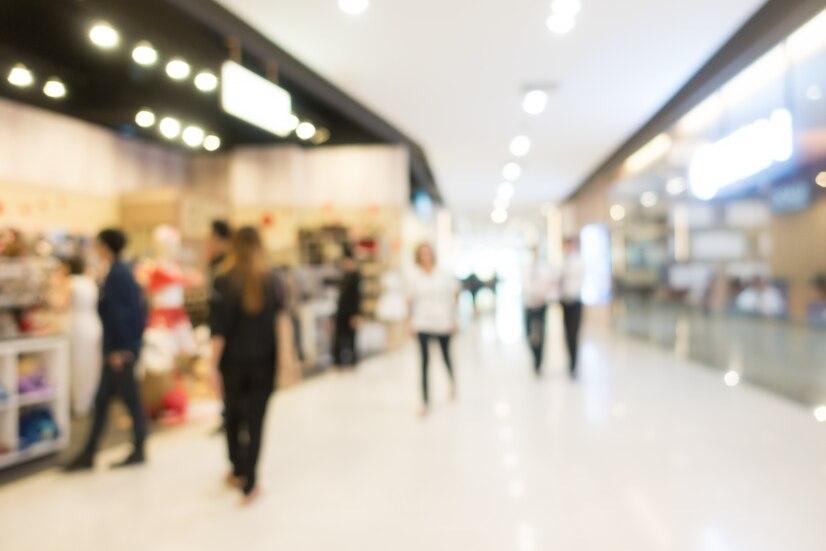

The `mall_customers.csv` dataset contains the following variables:

1. `CustomerID`: A unique identifier for each customer. It is an integer that increases by 1 for each customer.

2. `Gender`: The customer's gender. This is a categorical variable with two possible values: 'Male' and 'Female'.

3. `Age`: The customer's age. This is a numerical variable.

4. `Annual Income (k$)`: The customer's annual income in thousands of dollars. This is a numerical variable.

5. `Spending Score (1-100)`: The customer's spending score on a scale from 1 to 100. This is a numerical variable that indicates how much the customer spends or reflects their purchasing behavior.

The spending score measures how much a customer spends at a particular business over a given period. This metric is essential for understanding customer purchasing behavior and segmenting customers into groups with similar characteristics. But how is this score calculated, and where does it come from in a real company?

The spending score is derived from a combination of factors, such as visit frequency, average purchase value, and total spending over a specific period. Businesses often use customer tracking systems, such as loyalty programs, loyalty cards, or point-of-sale (POS) systems, to collect purchase data. These systems record each customer transaction, including the amount spent, items purchased, and visit frequency.

Using this information, businesses can calculate the spending score in various ways, such as assigning points to each purchase based on its value or frequency, or using more complex algorithms that consider multiple variables. The goal is to create a metric that accurately and meaningfully reflects each customer's purchasing behavior.

In the real world, spending scores are used across many industries, including retail, restaurants, hotels, and financial services. Businesses use them to better understand customers, identify purchasing patterns, design targeted marketing strategies, and improve the customer experience.

### **Content**

#### Import the required packages

In [1]:
# Install the required packages
%pip install scikit-learn
%pip install pandas
%pip install matplotlib
%pip install seaborn
%pip install ipywidgets
%matplotlib inline

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import the required packages
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

#### Load the dataset

In [3]:
# Load the 'mall_customers.csv' dataset
customers = pd.read_csv('mall_customers.csv')

#### Display the first 10 rows of the loaded dataset

In [4]:
# Display the first rows
customers.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [5]:
# Display information about the dataset
customers.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


array([[<Axes: title={'center': 'CustomerID'}>,
        <Axes: title={'center': 'Age'}>],
       [<Axes: title={'center': 'Annual Income (k$)'}>,
        <Axes: title={'center': 'Spending Score (1-100)'}>]], dtype=object)

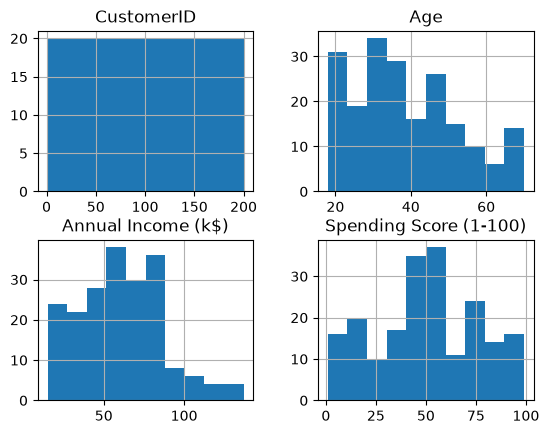

In [6]:
# Display histograms of the variables
customers.hist()

#### Remove columns that do not provide useful information for the analysis

The `CustomerID` column is a unique identifier for each customer. In most cases, identifiers like this do not provide useful information for data analysis or data mining models because they are not related to the other variables. Therefore, this column is commonly removed before analysis.

The pandas `drop` method removes the specified column (`'CustomerID'`) from the DataFrame. The `axis=1` argument indicates that we want to remove a column rather than a row. The resulting DataFrame is assigned back to the `customers` variable.

In [7]:
# Remove the 'CustomerID' column
customers = customers.drop('CustomerID', axis=1)
customers.head(10)

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,Male,19,15,39
1,Male,21,15,81
2,Female,20,16,6
3,Female,23,16,77
4,Female,31,17,40
5,Female,22,17,76
6,Female,35,18,6
7,Female,23,18,94
8,Male,64,19,3
9,Female,30,19,72


#### Encode the categorical 'Gender' column

We use the pandas `replace` method to replace values in the `Gender` column of the `customers` DataFrame.

- `customers['Gender']`: Selects the `Gender` column from the `customers` DataFrame.

- `replace({'Female': 0, 'Male': 1})`: Replaces values in the column according to the provided mapping. In this case, it replaces 'Female' with 0 and 'Male' with 1. This is called label encoding.

The purpose of this code is to convert the categorical `Gender` variable into a numerical variable, which is useful for calculating correlations between variables.

In [8]:
# Encode the 'Gender' variable
customers['Gender'] = customers['Gender'].replace({'Female': 0, 'Male': 1})
customers.head(10)

,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,1,21,15,81
2,0,20,16,6
3,0,23,16,77
4,0,31,17,40
5,0,22,17,76
6,0,35,18,6
7,0,23,18,94
8,1,64,19,3
9,0,30,19,72


#### Use `ydata_profiling` to profile the data

The `ydata_profiling` tool is very useful for exploratory data analysis. This Python library generates detailed data profiles from a pandas DataFrame, providing a quick, comprehensive overview of the data structure, relationships, and distributions.

With `ydata_profiling`, you can generate a comprehensive report from your dataset with just a few lines of code. The report includes descriptive statistics, variable distributions, correlations, missing values, and more. This can be extremely useful at the start of any data analysis or data mining project because it helps you understand your data before preprocessing or modeling.

Keep in mind that `ydata_profiling` is a data analysis tool and does not replace careful analysis or a thorough understanding of your data. Always verify and understand the results it provides.

In [9]:
# Install the ydata_profiling library
%pip install ydata-profiling
%pip install setuptools

# Import ProfileReport from ydata_profiling
# Note: ydata-profiling does not support Python 3.14 yet, so the import is wrapped in a try/except
try:
    from ydata_profiling import ProfileReport
    PROFILING_AVAILABLE = True
except ImportError:
    PROFILING_AVAILABLE = False
    print('ydata-profiling is not available in this environment, using a pandas summary instead.')

Note: you may need to restart the kernel to use updated packages.


ERROR: Ignored the following versions that require a different python version: 4.0.0 Requires-Python >=3.7,<3.11; 4.1.0 Requires-Python >=3.7,<3.12; 4.1.1 Requires-Python >=3.7,<3.12; 4.1.2 Requires-Python >=3.7,<3.12; 4.10.0 Requires-Python >=3.7,<3.13; 4.11.0 Requires-Python >=3.7,<3.13; 4.12.0 Requires-Python >=3.7,<3.13; 4.12.1 Requires-Python >=3.7,<3.13; 4.12.2 Requires-Python >=3.7,<3.13; 4.13.0 Requires-Python >=3.7,<3.13; 4.14.0 Requires-Python >=3.7,<3.13; 4.15.0 Requires-Python >=3.7,<3.13; 4.15.1 Requires-Python >=3.7,<3.13; 4.16.0 Requires-Python >=3.7,<3.13; 4.16.1 Requires-Python >=3.7,<3.13; 4.17.0 Requires-Python >=3.7,<3.14; 4.18.0 Requires-Python >=3.10,<3.14; 4.18.1 Requires-Python >=3.10,<3.14; 4.18.4 Requires-Python >=3.10,<3.14; 4.2.0 Requires-Python >=3.7,<3.12; 4.3.0 Requires-Python >=3.7,<3.12; 4.3.1 Requires-Python >=3.7,<3.12; 4.3.2 Requires-Python >=3.7,<3.12; 4.4.0 Requires-Python >=3.7,<3.12; 4.5.0 Requires-Python >=3.7,<3.12; 4.5.1 Requires-Python >=3.7,

Note: you may need to restart the kernel to use updated packages.
ydata-profiling is not available in this environment, using a pandas summary instead.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


- `customers`: The pandas DataFrame to profile.

- `title='Customer Data Profile Report'`: Sets the report title.

- `explorative=True`: Indicates that the report should be exploratory, including more information and analysis than a standard profiling report.

The data profiling report provides a quick overview of your dataset, including data types, unique values, missing values, descriptive statistics, correlations, and variable distributions.

To display the report, call the `customer_profile` object in a Jupyter Notebook cell.

In [10]:
# Generate the data profiling report
if PROFILING_AVAILABLE:
    customer_profile = ProfileReport(customers, title='Customer Data Profile Report', explorative=True)

,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


Missing values per column:


Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

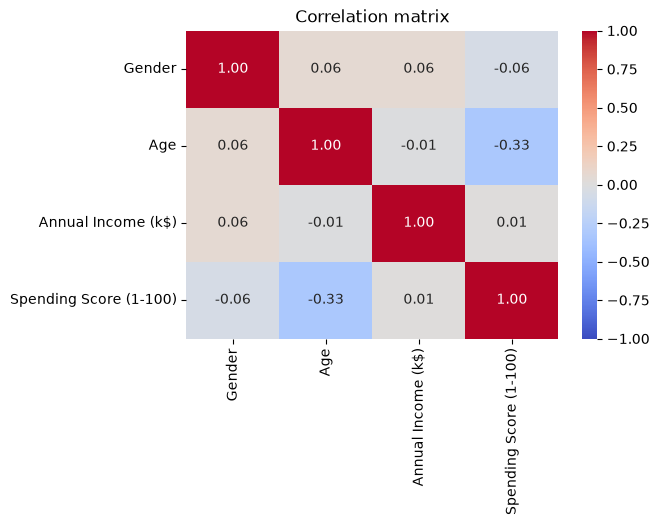

In [11]:
# Display the data profiling report
if PROFILING_AVAILABLE:
    customer_profile.to_notebook_iframe()
else:
    # Alternative: descriptive statistics, missing values and correlation matrix
    display(customers.describe())
    print('Missing values per column:')
    display(customers.isna().sum())
    plt.figure(figsize=(6, 4))
    sns.heatmap(customers.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
    plt.title('Correlation matrix')
    plt.show()

In [12]:
if PROFILING_AVAILABLE:
    customer_profile.to_file('customer_profile_report.html')

#### Plot the distributions of the variables

The distribution of variables in a dataset can provide valuable information about its characteristics. Here are some things to examine:

**Central tendency**: The mean and median indicate where the data are centered.

**Dispersion**: The standard deviation and interquartile range indicate how spread out the data are around the mean.

**Skewness**: A left or right skew may indicate outliers or a non-uniform distribution.

**Outliers**: Values significantly distant from the rest of the data may indicate measurement errors or natural variation.

**Multimodal distribution**: More than one peak may indicate subgroups within the data.

The scatter plot of `Annual Income (k$)` and `Spending Score (1-100)` reveals visible data groupings, suggesting that there are groups of customers with similar spending behavior relative to their annual income.

We create a new DataFrame containing only these two variables to examine these groupings more closely and apply clustering techniques to identify and define the groups more formally.

This can provide valuable information for marketing strategy by allowing customers to be segmented according to their spending behavior and income. This, in turn, can inform decisions about targeted offers and promotions, personalized customer communications, and more.

In [13]:
# Create a DataFrame containing only the 'Annual Income (k$)' and 'Spending Score (1-100)' columns
income_spending = customers[['Annual Income (k$)', 'Spending Score (1-100)']]
income_spending.head(10)

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40
5,17,76
6,18,6
7,18,94
8,19,3
9,19,72


#### Plot the distributions of 'Annual Income (k$)' and 'Spending Score (1-100)'

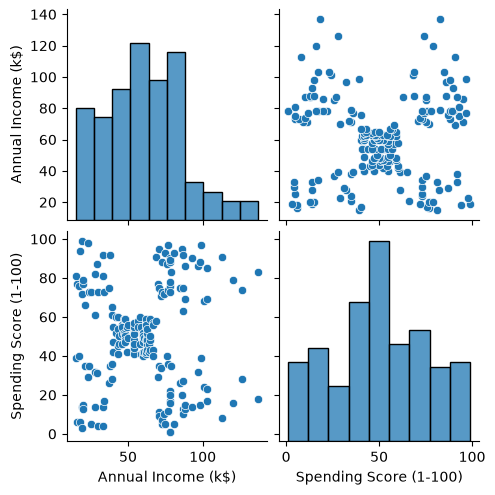

In [14]:
# Plot the distributions in income_spending
sns.pairplot(income_spending)

#### Cluster the 'income_spending' DataFrame using the KMeans algorithm

We use KMeans clustering on the `income_spending` DataFrame to find 2 clusters, then add the cluster labels to the data.

- `kmeans_model = KMeans(n_clusters=2)`: Creates a KMeans model with 2 clusters. The number of clusters is a parameter that must be specified.

- `kmeans_model.fit(income_spending)`: Fits the model to the `income_spending` data. KMeans attempts to find cluster centers that minimize the variance within each cluster.

- `income_spending['Cluster'] = kmeans_model.labels_`: After fitting the model, the `labels_` attribute provides the cluster label for each data point. This line adds the labels as a new column in the `income_spending` DataFrame.

- `income_spending.head(10)`: Displays the first 10 rows of the `income_spending` DataFrame, now including the `Cluster` column.

In [15]:
# Instantiate the KMeans model
kmeans_model = KMeans(n_clusters=2, random_state=75)

# Fit the model to the data
kmeans_model.fit(income_spending)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",75
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 2)","[

In [16]:
# Copy the 'income_spending' DataFrame to preserve the original and add the clusters
income_spending_cluster = income_spending.copy()

# Get the cluster labels assigned to each customer
income_spending_cluster['Cluster'] = kmeans_model.labels_

# Display the first rows of 'income_spending_cluster'
income_spending_cluster.head(10)

,Annual Income (k$),Spending Score (1-100),Cluster
0,15,39,1
1,15,81,1
2,16,6,1
3,16,77,1
4,17,40,1
5,17,76,1
6,18,6,1
7,18,94,1
8,19,3,1
9,19,72,1


In [17]:
income_spending_cluster.tail(10)

,Annual Income (k$),Spending Score (1-100),Cluster
190,103,23,0
191,103,69,0
192,113,8,0
193,113,91,0
194,120,16,0
195,120,79,0
196,126,28,0
197,126,74,0
198,137,18,0
199,137,83,0


We create a pair plot of the `income_spending` variables and color the points according to the clusters identified by KMeans. This helps us visualize how the clusters are distributed in the variable space.

- `sns.pairplot(income_spending)`: Creates a pair plot of all variables in the DataFrame. A pair plot shows the relationship between each pair of variables in a dataset.

- `hue='Cluster'`: Specifies that points in the plot should be colored according to the `Cluster` column. This makes it possible to visualize the distribution of clusters for each pair of variables.

- `palette='viridis'`: Sets the color palette for the clusters. 'viridis' is a perceptually uniform palette that is easy to interpret.

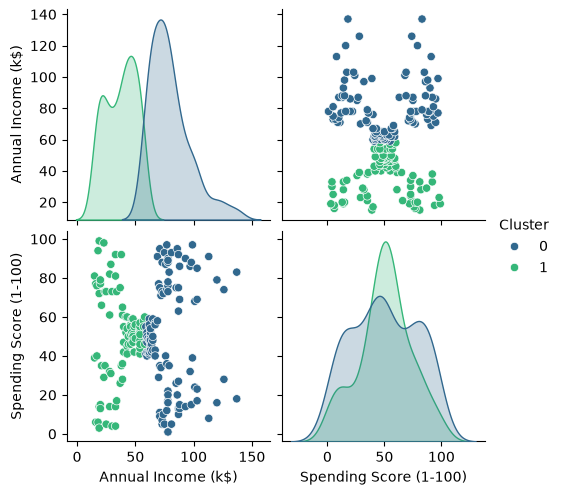

In [18]:
# Display the clusters generated by the KMeans model
sns.pairplot(income_spending_cluster, hue='Cluster', palette='viridis')

In [19]:
# Get the inertia of the KMeans model
inertia = kmeans_model.inertia_
inertia

181363.595959596

Finally, we can use the previously fitted KMeans model to predict the cluster of a new customer based on their features.

- `new_customer = [ , ]`: Creates a list representing a new customer's data. The values correspond to the customer's annual income and spending score.

- `new_customer_cluster = kmeans_model.predict([new_customer])`: Uses the KMeans model's `predict` method to predict which cluster the new customer belongs to. The method takes a list of lists as input, where each inner list represents one customer's data. Here, the input contains only one customer: `[new_customer]`.

- `print('The new customer belongs to cluster:', new_customer_cluster)`: Prints the cluster assigned to the new customer. The `predict` method returns a list of cluster labels, one for each customer in the input. Here, the list contains a single label.

In [20]:
# New customer with Annual Income (k$) = 50 and Spending Score (1-100) = 50
new_customer_cluster = kmeans_model.predict([[50, 50]])
new_customer_cluster

c:\Users\jainca\Downloads\Actividad 4\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


array([1], dtype=int32)

### **Group Assignment**

We can see that 2 may not be the optimal value of $k$. Let's try to find the best value of $k$ using the elbow method. This method involves running the KMeans clustering algorithm for a range of $k$ values and then plotting the number of clusters against the sum of squared distances within each cluster (inertia).

> Inertia is calculated by measuring the distance between a data point and its centroid, squaring the distance, and summing those squared distances for all data points in the cluster.

The 'elbow' in this plot—the inflection point where the rate of decrease becomes significantly smaller—may indicate a good value for $k$.

### **Code (4 points)**

In [21]:
# Write your code here to find the optimal number of clusters using the elbow method.
# Fit KMeans for k = 1..10 and store the inertia of each model
k_values = range(1, 11)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=75, n_init=10)
    model.fit(income_spending)
    inertias.append(model.inertia_)

elbow_results = pd.DataFrame({'k': list(k_values), 'Inertia': inertias})
elbow_results

,k,Inertia
0,1,269981.280000
1,2,181363.595960
2,3,106348.373062
3,4,73679.789039
4,5,44448.455448
5,6,37265.865205
6,7,30227.606513
7,8,25095.703210
8,9,21913.929201
9,10,19968.359199


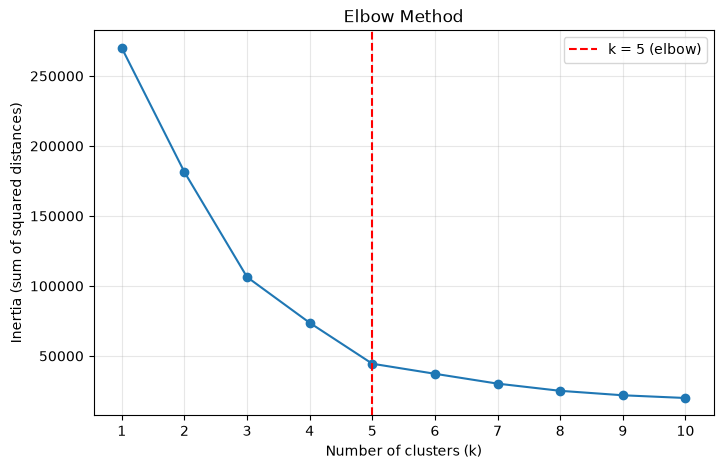

In [22]:
# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker='o')
plt.axvline(x=5, color='red', linestyle='--', label='k = 5 (elbow)')
plt.xticks(list(k_values))
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (sum of squared distances)')
plt.title('Elbow Method')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

To double-check the elbow, I also calculated the **silhouette score**, which measures how well each point is separated from the other clusters (values closer to 1 are better).

In [23]:
# Silhouette score for k = 2..10
from sklearn.metrics import silhouette_score

silhouette_scores = []
for k in range(2, 11):
    labels = KMeans(n_clusters=k, random_state=75, n_init=10).fit_predict(income_spending)
    silhouette_scores.append(silhouette_score(income_spending, labels))

elbow_results['Silhouette'] = [None] + silhouette_scores
elbow_results.round(3)

,k,Inertia,Silhouette
0,1,269981.280,NaN
1,2,181363.596,0.297
2,3,106348.373,0.468
3,4,73679.789,0.493
4,5,44448.455,0.554
5,6,37265.865,0.538
6,7,30227.607,0.528
7,8,25095.703,0.457
8,9,21913.929,0.458
9,10,19968.359,0.438


**Selected k:** The inertia drops sharply up to **k = 5** (from about 270,000 with k = 1 to about 44,000 with k = 5). After that the decrease is much smaller (about 37,000 with k = 6 and 30,000 with k = 7), so the elbow is at k = 5. The silhouette score also reaches its maximum (about 0.55) at k = 5.

I retrain KMeans with **k = 5** and assign it to `kmeans_model`, so the analysis questions use the model with the optimal number of clusters.

In [24]:
# Final model with the optimal k
optimal_k = 5
kmeans_model = KMeans(n_clusters=optimal_k, random_state=75, n_init=10)
kmeans_model.fit(income_spending)

income_spending_cluster = income_spending.copy()
income_spending_cluster['Cluster'] = kmeans_model.labels_
print('Inertia with k = 5:', round(kmeans_model.inertia_, 1))
income_spending_cluster.head(10)

Inertia with k = 5: 44448.5


,Annual Income (k$),Spending Score (1-100),Cluster
0,15,39,4
1,15,81,1
2,16,6,4
3,16,77,1
4,17,40,4
5,17,76,1
6,18,6,4
7,18,94,1
8,19,3,4
9,19,72,1


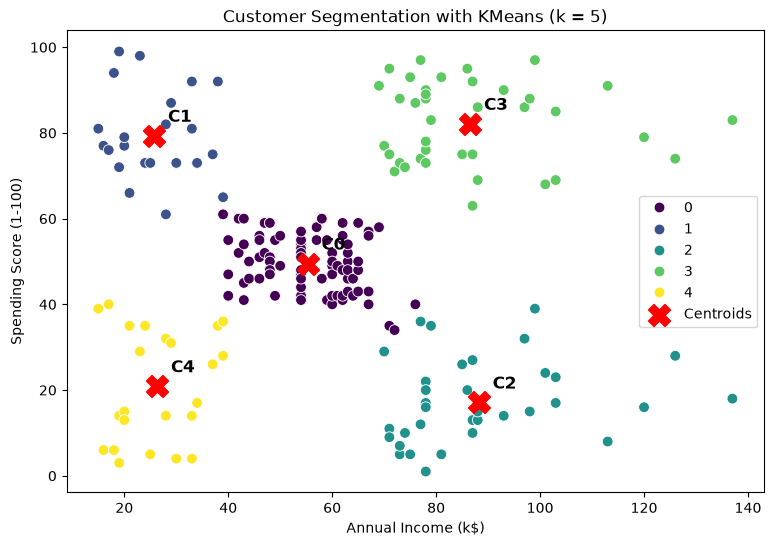

In [25]:
# Plot the 5 clusters and their centroids
centroids = kmeans_model.cluster_centers_

plt.figure(figsize=(9, 6))
sns.scatterplot(data=income_spending_cluster, x='Annual Income (k$)', y='Spending Score (1-100)',
                hue='Cluster', palette='viridis', s=60)
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='X', s=250, label='Centroids')
for i, (x, y) in enumerate(centroids):
    plt.annotate(f'C{i}', (x, y), textcoords='offset points', xytext=(10, 10), fontsize=12, weight='bold')
plt.title('Customer Segmentation with KMeans (k = 5)')
plt.legend()
plt.show()

In [26]:
# Profile of each cluster, including the variables that were not used in the model
customers_clustered = customers.copy()
customers_clustered['Cluster'] = kmeans_model.labels_

cluster_profile = customers_clustered.groupby('Cluster').agg(
    Customers=('Age', 'size'),
    Mean_Age=('Age', 'mean'),
    Mean_Income=('Annual Income (k$)', 'mean'),
    Mean_Spending=('Spending Score (1-100)', 'mean'),
    Male_Share=('Gender', lambda g: g.astype(float).mean()),
).round(1)

# Label each cluster by comparing its income and spending with the overall mean
income_mean = customers['Annual Income (k$)'].mean()
spending_mean = customers['Spending Score (1-100)'].mean()

def describe_cluster(row):
    if abs(row['Mean_Income'] - income_mean) < 10 and abs(row['Mean_Spending'] - spending_mean) < 10:
        return 'Medium income - Medium spending'
    income = 'High income' if row['Mean_Income'] > income_mean else 'Low income'
    spending = 'High spending' if row['Mean_Spending'] > spending_mean else 'Low spending'
    return f'{income} - {spending}'

cluster_profile['Segment'] = cluster_profile.apply(describe_cluster, axis=1)
cluster_profile

,Customers,Mean_Age,Mean_Income,Mean_Spending,Male_Share,Segment
Cluster,,,,,,
0,81,42.7,55.3,49.5,0.4,Medium income - Medium spending
1,22,25.3,25.7,79.4,0.4,Low income - High spending
2,35,41.1,88.2,17.1,0.5,High income - Low spending
3,39,32.7,86.5,82.1,0.5,High income - High spending
4,23,45.2,26.3,20.9,0.4,Low income - Low spending


Analysis Questions - New Dataset

Assessment Rubric (10 points)

Phase 1 - Dataset and Features (3 points)
1 point: The dataset is locally sourced, and its source is identified.
1 point: Every dataset variable is described.
1 point: The features selected for the model are justified.

Phase 2 - KMeans Modeling (4 points)
2 points: The elbow method is applied to a range of k values, and the plot and selected k are provided.
2 points: KMeans is fitted using the selected k, and the resulting clusters are visualized.

Phase 3 - Findings (3 points)
1 point each: Three findings are stated, and each is supported by the clustering results.

### **Analysis Questions - Mall Customers Dataset (6 points)**

***1. Which customer group would you focus on?***

I would focus on the **high income - low spending** group (cluster 2, 35 customers, average income of about 88 k$, average spending score of about 17, average age of about 41). This group has the biggest growth potential: they have the money to buy but currently spend very little at the mall, so getting them to spend more would have a big impact on sales.

The **high income - high spending** group (cluster 3, 39 customers, average age of about 33) is also important, but for them the goal is to **keep them** as customers rather than attract them.

***2. What actionable strategies could we recommend to increase spending at the shopping mall?***

Strategies for each segment found by KMeans:

- **High income - Low spending:** attract them with premium brands, exclusive experiences (private events, pre-sales, personal shoppers) and convenience services (preferred parking, home delivery). It would also be useful to run surveys to understand why they don't buy, since the current offer may not match what they are looking for.
- **High income - High spending:** a tiered loyalty program (VIP) with accumulated benefits, to keep their spending high and avoid losing them to competitors.
- **Medium income - Medium spending** (the largest group, 81 customers): cross-selling and volume promotions (2x1, bundles, coupons for the next visit) to increase the average ticket and visit frequency.
- **Low income - High spending** (young customers, around 25 years old): discounts, installment payments and social media promotions. They spend a lot compared to their income, so they are price-sensitive but very active buyers.
- **Low income - Low spending:** entry-level offers and low-cost products. This is not a priority segment for a big marketing budget.

In general, the segments can be used to **personalize communication** (email, app, notifications) instead of sending the same campaign to everyone.

***3. Which group would a new customer with an annual income (k$) of 110 and a spending score of 21 belong to?***

In [27]:
# Create a record with the new customer's values and assign it to a cluster using the trained KMeans model.
new_customer = [110, 21]
# Use the KMeans model's predict method to predict the cluster of the new customer.
new_customer_cluster = kmeans_model.predict(pd.DataFrame([new_customer], columns=income_spending.columns))

print('The new customer belongs to cluster:', new_customer_cluster[0])
cluster_profile.loc[new_customer_cluster]

The new customer belongs to cluster: 2


,Customers,Mean_Age,Mean_Income,Mean_Spending,Male_Share,Segment
Cluster,,,,,,
2,35,41.1,88.2,17.1,0.5,High income - Low spending


The new customer (annual income of 110 k$ and spending score of 21) belongs to **cluster 2: high income - low spending**. This makes sense because their income is well above the average (about 60 k$) and their spending score is well below the average (about 50), so the closest centroid is the one of this segment. This is exactly the type of customer we recommended focusing on in question 1.

## **New Dataset: Ecuadorian Household Income and Spending (ENIGHUR 2024-2025)**

### **Phase 1 - Dataset and Features**

#### Source

The dataset comes from the **Encuesta Nacional de Ingresos y Gastos de los Hogares Urbanos y Rurales (ENIGHUR) 2024-2025**, published by Ecuador's **Instituto Nacional de Estadística y Censos (INEC)**. It is a national survey that records how much money Ecuadorian households earn and spend each month, so it is a local equivalent of the mall dataset (income vs. spending behavior).

- Official page: https://www.ecuadorencifras.gob.ec/encuesta-nacional-de-ingresos-y-gastos-de-los-hogares-urbanos-y-rurales/
- Original file: `ENIGHUR25_HOGARES_AGREGADOS` (household-level aggregates), from the open data package `DATOS_ABIERTOS_ENIGHUR_v1.zip`. The category labels (area, region, gender, etc.) were taken from the SPSS version of the same file.

From the original table (35,398 households and 271 columns), a few columns were selected, the numeric codes were replaced with their labels, and one household with a missing income was removed. The result is `enighur_households.csv` (35,397 households).

In [28]:
# Load the 'enighur_households.csv' dataset
households = pd.read_csv('enighur_households.csv')
households.head(10)

,HouseholdID,Area,Region,Head Gender,Head Age Group,Head Education,Household Size,Monthly Income ($),Monthly Spending ($)
0,1,Urban,Highlands,Female,65+,Primary,5,607.61,621.43
1,2,Urban,Highlands,Female,45-64,Secondary,2,1010.30,1241.13
2,3,Urban,Highlands,Male,25-44,University/Postgraduate,4,2188.92,1667.69
3,4,Urban,Highlands,Male,25-44,Secondary,4,927.51,785.05
4,5,Urban,Highlands,Female,45-64,Primary,4,1233.22,789.42
5,6,Urban,Highlands,Male,25-44,Secondary,4,1860.95,1725.09
6,7,Urban,Highlands,Female,25-44,University/Postgraduate,2,2138.00,1537.27
7,8,Urban,Highlands,Male,25-44,Secondary,5,2981.14,1767.48
8,9,Urban,Highlands,Female,45-64,Primary,2,939.17,679.81
9,10,Urban,Highlands,Female,25-44,Secondary,3,1685.26,1256.58


In [29]:
# Display information about the dataset
households.info()

<class 'pandas.DataFrame'>
RangeIndex: 35397 entries, 0 to 35396
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   HouseholdID           35397 non-null  int64  
 1   Area                  35397 non-null  str    
 2   Region                35397 non-null  str    
 3   Head Gender           35397 non-null  str    
 4   Head Age Group        35397 non-null  str    
 5   Head Education        35397 non-null  str    
 6   Household Size        35397 non-null  int64  
 7   Monthly Income ($)    35397 non-null  float64
 8   Monthly Spending ($)  35397 non-null  float64
dtypes: float64(2), int64(2), str(5)
memory usage: 2.4 MB


#### Variable description

1. `HouseholdID`: A unique identifier for each household (integer, increases by 1).
2. `Area`: Whether the household is in an `Urban` or `Rural` area (categorical).
3. `Region`: Natural region of Ecuador: `Coast`, `Highlands`, `Amazon` or `Galapagos` (categorical).
4. `Head Gender`: Gender of the head of household, `Male` or `Female` (categorical).
5. `Head Age Group`: Age group of the head of household: `Under 25`, `25-44`, `45-64`, `65+` (categorical, ordinal).
6. `Head Education`: Highest education level of the head of household, from `No education` to `University/Postgraduate` (categorical, ordinal).
7. `Household Size`: Number of people living in the household (numerical).
8. `Monthly Income ($)`: Total current monthly income of the household in US dollars, including monetary and non-monetary income (numerical). INEC variable `ing_cor_tot`.
9. `Monthly Spending ($)`: Total current monthly spending of the household in US dollars (numerical). INEC variable `gas_cor_tot`.

We also create one derived variable:

10. `Spending Ratio (%)`: Monthly spending as a percentage of monthly income. A value of 100 means the household spends everything it earns, below 100 means it saves, and above 100 means it spends more than it earns (savings, debt or help from others).

In [30]:
# Create the 'Spending Ratio (%)' variable
households['Spending Ratio (%)'] = households['Monthly Spending ($)'] / households['Monthly Income ($)'] * 100
households.describe().round(1)

,HouseholdID,Household Size,Monthly Income ($),Monthly Spending ($),Spending Ratio (%)
count,35397.0,35397.0,35397.0,35397.0,35397.0
mean,17699.0,3.3,1100.6,890.9,89.9
std,10218.4,1.7,974.5,698.3,76.0
min,1.0,1.0,10.8,30.0,4.8
25%,8850.0,2.0,500.0,458.2,75.0
50%,17699.0,3.0,817.3,706.9,89.5
75%,26548.0,4.0,1366.7,1092.4,101.7
max,35397.0,20.0,17701.0,12521.0,13099.0


In [31]:
# Correlation between income, spending and the spending ratio
households[['Monthly Income ($)', 'Monthly Spending ($)', 'Spending Ratio (%)']].corr().round(2)

,Monthly Income ($),Monthly Spending ($),Spending Ratio (%)
Monthly Income ($),1.00,0.86,-0.13
Monthly Spending ($),0.86,1.00,0.01
Spending Ratio (%),-0.13,0.01,1.00


#### Feature selection

The model uses **`Monthly Income ($)`** and **`Spending Ratio (%)`**:

- They play the same role as `Annual Income (k$)` and `Spending Score (1-100)` in the mall dataset: how much the household earns and how much of that it spends.
- We do **not** use `Monthly Spending ($)` directly because it is strongly correlated with income (see the matrix above). Clustering income vs. spending would only split households into income bands along a diagonal. The spending ratio is almost independent of income, so it adds new information about behavior (savers vs. households that spend more than they earn).
- The categorical variables (area, region, gender, age, education) are **not** used to train the model. We use them afterward to describe each cluster.

Two preprocessing steps are needed:

1. **Outliers:** a few households report very high incomes or ratios. KMeans uses means, so these points would pull the centroids, so we remove households above the 99th percentile of either variable.
2. **Scaling:** income is in dollars (hundreds to thousands) and the ratio is a percentage (around 30-180). Without scaling, income would dominate the distances, so both variables are standardized with `StandardScaler`.

In [32]:
from sklearn.preprocessing import StandardScaler

features = ['Monthly Income ($)', 'Spending Ratio (%)']

# Remove households above the 99th percentile of income or spending ratio
limits = households[features].quantile(0.99)
households_model = households[(households[features] <= limits).all(axis=1)].reset_index(drop=True)
print('Households before:', len(households), '- after removing outliers:', len(households_model))

# Standardize the two features (mean 0, standard deviation 1)
scaler = StandardScaler()
income_ratio = pd.DataFrame(scaler.fit_transform(households_model[features]), columns=features)
income_ratio.describe().round(2)

Households before: 35397 - after removing outliers: 34691


,Monthly Income ($),Spending Ratio (%)
count,34691.00,34691.00
mean,0.00,0.00
std,1.00,1.00
min,-1.28,-3.96
25%,-0.69,-0.61
50%,-0.30,0.07
75%,0.37,0.64
max,4.84,4.21


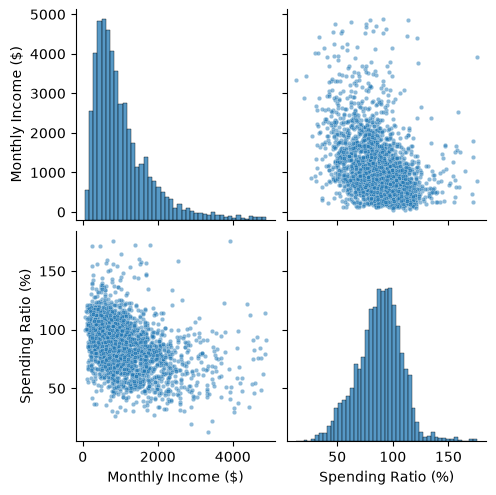

In [33]:
# Plot the distributions of the two features (a 3,000-household sample keeps the plot readable)
sns.pairplot(households_model[features].sample(3000, random_state=75), plot_kws={'s': 10, 'alpha': 0.5})

### **Phase 2 - KMeans Modeling**

#### Elbow method

In [34]:
# Fit KMeans for k = 1..10 and store the inertia of each model
hh_k_values = range(1, 11)
hh_inertias = []

for k in hh_k_values:
    model = KMeans(n_clusters=k, random_state=75, n_init=10)
    model.fit(income_ratio)
    hh_inertias.append(model.inertia_)

hh_elbow_results = pd.DataFrame({'k': list(hh_k_values), 'Inertia': hh_inertias})
hh_elbow_results['Reduction (%)'] = (-hh_elbow_results['Inertia'].pct_change() * 100)
hh_elbow_results.round(1)

,k,Inertia,Reduction (%)
0,1,69382.0,NaN
1,2,37308.9,46.2
2,3,26212.6,29.7
3,4,21044.0,19.7
4,5,17177.7,18.4
5,6,14619.9,14.9
6,7,12652.6,13.5
7,8,11263.7,11.0
8,9,10066.4,10.6
9,10,9047.3,10.1


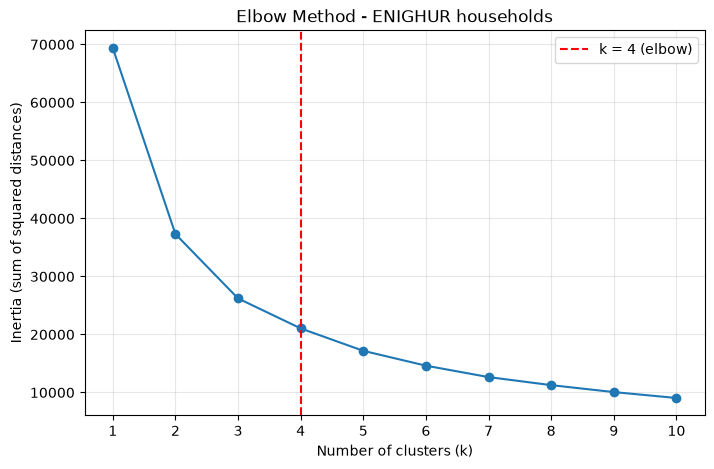

In [35]:
# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(list(hh_k_values), hh_inertias, marker='o')
plt.axvline(x=4, color='red', linestyle='--', label='k = 4 (elbow)')
plt.xticks(list(hh_k_values))
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia (sum of squared distances)')
plt.title('Elbow Method - ENIGHUR households')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The inertia drops sharply at first (-46% from k = 1 to 2, -30% from 2 to 3, -20% from 3 to 4). After **k = 4** each additional cluster only reduces the inertia by between 10% and 18%, so the curve flattens. We choose **k = 4**: it is where the elbow ends, and four groups are still easy to interpret (two income levels × saving or overspending).

#### Final KMeans model

In [36]:
# Fit the final model with k = 4
hh_optimal_k = 4
hh_kmeans_model = KMeans(n_clusters=hh_optimal_k, random_state=75, n_init=10)
hh_kmeans_model.fit(income_ratio)

households_clustered = households_model.copy()
households_clustered['Cluster'] = hh_kmeans_model.labels_
print('Inertia with k = 4:', round(hh_kmeans_model.inertia_, 1))
households_clustered['Cluster'].value_counts().sort_index()

Inertia with k = 4: 21044.0


Cluster
0     3479
1    14755
2     8835
3     7622
Name: count, dtype: int64

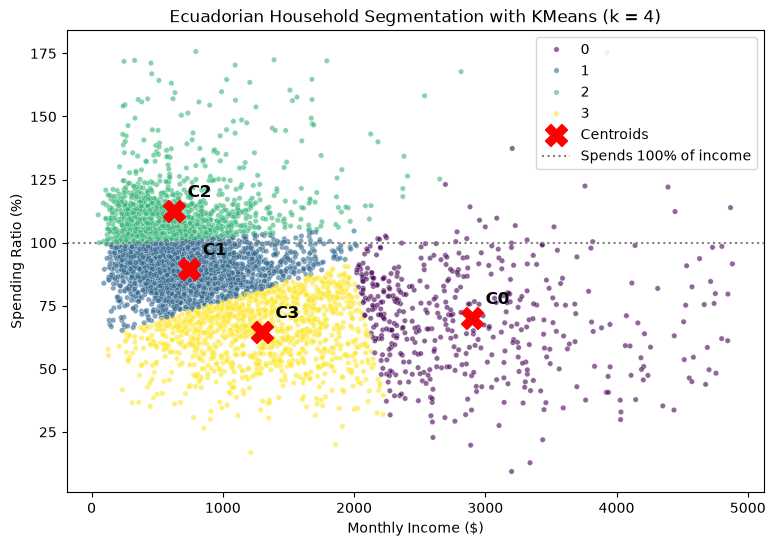

In [37]:
# Plot the clusters and their centroids (centroids converted back to dollars and percentages)
hh_centroids = scaler.inverse_transform(hh_kmeans_model.cluster_centers_)
plot_sample = households_clustered.sample(5000, random_state=75)

plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_sample, x='Monthly Income ($)', y='Spending Ratio (%)',
                hue='Cluster', palette='viridis', s=15, alpha=0.6)
plt.scatter(hh_centroids[:, 0], hh_centroids[:, 1], c='red', marker='X', s=250, label='Centroids')
for i, (x, y) in enumerate(hh_centroids):
    plt.annotate(f'C{i}', (x, y), textcoords='offset points', xytext=(10, 10), fontsize=12, weight='bold')
plt.axhline(y=100, color='gray', linestyle=':', label='Spends 100% of income')
plt.title('Ecuadorian Household Segmentation with KMeans (k = 4)')
plt.legend()
plt.show()

In [38]:
# Profile of each cluster, including the variables that were not used in the model
hh_cluster_profile = households_clustered.groupby('Cluster').agg(
    Households=('HouseholdID', 'size'),
    Mean_Income=('Monthly Income ($)', 'mean'),
    Mean_Spending=('Monthly Spending ($)', 'mean'),
    Mean_Ratio=('Spending Ratio (%)', 'mean'),
    Mean_Size=('Household Size', 'mean'),
    Urban_Share=('Area', lambda s: (s == 'Urban').mean() * 100),
    Female_Head_Share=('Head Gender', lambda s: (s == 'Female').mean() * 100),
    University_Head_Share=('Head Education', lambda s: (s == 'University/Postgraduate').mean() * 100),
).round(1)
hh_cluster_profile['Share (%)'] = (hh_cluster_profile['Households'] / len(households_clustered) * 100).round(1)

# Label each cluster by its income level and whether it saves or overspends
hh_income_mean = households_model['Monthly Income ($)'].mean()

def describe_household_cluster(row):
    income = 'High income' if row['Mean_Income'] > 2 * hh_income_mean else (
        'Medium income' if row['Mean_Income'] > hh_income_mean else 'Low income')
    behavior = 'Overspends' if row['Mean_Ratio'] > 100 else ('Saves' if row['Mean_Ratio'] < 75 else 'Spends most')
    return f'{income} - {behavior}'

hh_cluster_profile['Segment'] = hh_cluster_profile.apply(describe_household_cluster, axis=1)
hh_cluster_profile

,Households,Mean_Income,Mean_Spending,Mean_Ratio,Mean_Size,Urban_Share,Female_Head_Share,University_Head_Share,Share (%),Segment
Cluster,,,,,,,,,,
0,3479,2894.5,2012.6,70.3,4.0,85.4,25.8,47.8,10.0,High income - Saves
1,14755,743.9,669.4,89.6,3.2,62.8,38.8,10.0,42.5,Low income - Spends most
2,8835,624.4,713.3,112.5,3.1,66.3,44.9,11.0,25.5,Low income - Overspends
3,7622,1294.7,842.4,64.5,3.5,64.4,32.2,20.9,22.0,Medium income - Saves


In [39]:
# Distribution of each region across the clusters (% of the region's households)
(pd.crosstab(households_clustered['Region'], households_clustered['Cluster'], normalize='index') * 100).round(1)

Cluster,0,1,2,3
Region,,,,
Amazon,9.3,42.0,23.2,25.5
Coast,6.7,47.6,29.7,16.0
Galapagos,42.2,24.6,18.4,14.8
Highlands,11.0,40.0,23.4,25.6


### **Phase 3 - Findings**

**Finding 1 - One in four households spends more than it earns.**
Cluster 2 (*Low income - Overspends*, 8,835 households, 25.5% of the sample) has an average income of about \$624 per month but spends about \$713, a spending ratio of **112%**. These households cover the gap with savings, debt or help from relatives. It is also the group with the highest share of **female heads of household (44.9%)**, compared with 25.8% in the high-income group. It is concentrated on the **Coast**, where 29.7% of households fall in this cluster (vs. about 23% in the Highlands and Amazon).

**Finding 2 - Higher income means saving a larger share, and the high-income group is small and urban.**
Only 10% of households belong to Cluster 0 (*High income - Saves*, about \$2,895 per month). They spend about \$2,013, much more in dollars than any other group, but only **70%** of their income. This group is **85.4% urban**, and **47.8%** of the heads of household have a university degree or postgraduate studies, compared with 10-11% in the two low-income clusters. Education is the variable that best separates this segment, even though it was not used to train the model.

**Finding 3 - Income alone does not explain spending behavior: two low-income groups behave very differently.**
Clusters 1 and 2 have similar incomes (\$744 and \$624 per month) and similar household sizes (3.2 and 3.1 people), but Cluster 1 spends **90%** of its income and Cluster 2 spends **112%**. Cluster 3 (*Medium income - Saves*, about \$1,295 per month) is the group that saves the largest share, spending only **64.5%** of its income. This is why the spending ratio was a better feature than total spending: it separates savers from overspenders at the same income level, the same way the Spending Score separated customers in the mall dataset. Also, **Galapagos** stands out: 42.2% of its households fall in the high-income cluster, compared with 6.7-11% in the other regions, which matches its higher cost of living and tourism-based economy. 